In [14]:
import numpy as np
import matplotlib.pyplot as plt

La primera ley de Fick es
$$ J=-D\frac{\partial C}{\partial x}$$

$D$ es un parametro que determina la rapidez con la que el $CO_2$ se difunde en el líquido.

- $L$: espesor del líquido (mm)
- $\Delta t$: paso temporal (s)
- $\Delta x$: distancia espacil $(\mu m)$
- `t_final`: tiempo simulado (s)
- $k$: constante de consumo superficial (m/s)

$$r = D \frac{\Delta t}{(\Delta x)^2}

In [15]:


L = 1e-3
D = 1.9e-9
k = 1e-4
C_bulk = 33.0  # Concentración exterior

N = 50  # Número de intervalos
dx = L / N

dt = 0.1
t_final = 10
n_steps = int(t_final / dt)

r = D * dt / dx**2

print(f"dx = {dx:.3e} m")
print(f"r = {r:.4f}")

dx = 2.000e-05 m
r = 0.4750


Suponemos que la cantidad de $CO_2$ que consume el electrodo por unidad de área y por unididad de tiempo es igual ala concentración de $CO_2$ justo en la superficie $(C_s)$ del electrodo multiplicada por un factor de proporcionalidad $k$ que dice qué tan ráido consume el electrodo el $CO_2$ disponible.

$$ J_{consumo} = kC_s $$

---

Como tenemos concentraciones en dos posiciones, podemos aproximar la derivada

$$\frac{\partial C}{\partial x}\approx \frac{C_1-C_0}{\Delta x}$$

Y al sustituir la primera ley de Fick $(J=-D\partial C/\partial x)$ queda

$$ J\approx -D\frac{C_1-C_0}{\Delta x}$$

---

Suponemos que no hay acomulción de $CO_2$ en la superficie, entonces el fllujo que llega por difusión debe ser igual al consumo:

$$ J_{dif}=J_{consumo} $$

Sustituyendo

$$D\frac{C_1-C_0}{\Delta x}=kC_0$$

De aquí podemos despejar $C_0$

$$ C_0 = \frac{D}{D+k\Delta x}C_1



In [16]:
x = np.linspace(0, L, N + 1)
t = np.arange(n_steps + 1) * dt

C = np.full(N + 1, C_bulk)

alpha = D / (D + k * dx)

C[0] = alpha * C[1]
C[-1] = C_bulk

$C$ contiene la concentración en todos los puntos en un instante. a medida que avanza el tiempo las concentraciones cambian, entonces necesitamos guardar una copia de $C$ en cada instante.

Creamos una matriz de ceros con dimension (número de instantes temporales que vamos a guardar INCLUIDO EL INICIAL)$\times$ (número de puntos iniciales donde calculamos la concentración)

El `C.copy` va guardando el perfil de concentración en la $n$ de la matriz

In [17]:
C_history = np.zeros((n_steps + 1, N + 1))
C_history[0] = C.copy()

La segunda ley de Fick es
$$ \frac{\partial C}{\partial t}=D\frac{\partial^2 C}{\partial x^2}$$

Con un desarrollo que esta en el notion llegamos a 

$$C_i^{n+1}=C_i^{n}+r(C_{i+1}^n-2C_i^n+C_{i-1}^n)$$

- `C[1:N]` es la concentración actual $(C_i^n)$
- `C[2:N+1]` es la concentración del vecino a la derecha $(C_{i+1}^n)$
- `C[0:N-1]` concentración del vecino izquierdo $(C_{i-1}^n)$
- `r` es $D\, \Delta t / (\Delta x)^2$
- `C_new[1:N]` es la concentración en el instante siguiente $(C_i^{n+1})$ 

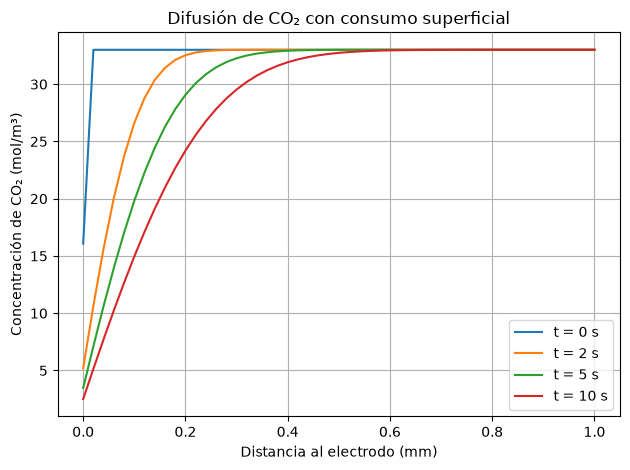

In [ ]:
for n in range(n_steps):

    C_new = C.copy()

    C_new[1:N] = C[1:N] + r * (
        C[2:N+1] - 2*C[1:N] + C[0:N-1]
    )

    C_new[0] = alpha * C_new[1]

    C_new[-1] = C_bulk

    # avanzar al siguiente instante
    C = C_new
    C_history[n + 1] = C.copy()

# 7. Graficar perfiles de concentración
for tiempo in [0, 2, 5, 10]:
    indice = int(tiempo / dt)
    plt.plot(
        x * 1e3,
        C_history[indice],
        label=f"t = {tiempo} s"
    )

plt.xlabel("Distancia al electrodo (mm)")
plt.ylabel("Concentración de CO₂ (mol/m³)")
plt.title("Difusión de CO₂ con consumo superficial")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()